# Lesson 9 — Reconstructing an Image by Training Gaussians

[Course plan](../../README.md) · [Previous lesson](lesson-08.ipynb) · [Русский](../ru/lesson-09.ipynb)

In the spot editor, we moved every number by hand. Then we taught one bell curve to find its center. Now a collection of colored spots replaces the single bell, and a small image replaces the curve. The loop stays the same: render, compare, compute gradients, update parameters.

We'll start with colorful geometric shapes. Their straight edges and thin stripe make it easy to see where soft spots have enough flexibility and where the image remains blurry. There is no hidden photograph already decomposed into ready-made Gaussians. The target is an ordinary RGB array that the model gradually approaches.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
import math
import numpy as np
import torch
from IPython.display import display

course_root = next(folder for folder in [Path.cwd(), *Path.cwd().parents]
                   if (folder / "training_math.py").is_file())
if str(course_root) not in sys.path:
    sys.path.insert(0, str(course_root))

from training_math import (chain_example, autograd_check, fit_one_gaussian,
                           make_target, initialize, render_torch, projected_step,
                           fit_image, parameters_scene, load_image, small_cpu_work)
from training_demos import (chain_figure, learning_figure, autograd_lab,
                            demo_fit, fitting_figure, detail_figure, fitting_lab)
LANG = 'en'

## 1. Before, After, and Everything Between

The main example uses $64$ spots, a $32\times32$ image, initial scale $0.55$, and learning rate $\eta=4$. Centers start on a grid. Initial colors are sampled from the target near each center, with a little white mixed in. This is a useful initialization hint, so the first image is not random noise.

After $120$ updates, MSE falls from about $0.032308$ to $0.012089$. The colored regions become more recognizable, but the error does not vanish. The difference map shows substantial error remaining along boundaries. The spot count, initial scale, and starting positions all change the result.

“Target” switches between shapes, a flower, and a fine checker pattern. The checker makes the limits of a coarse representation particularly visible. Changing settings defines a new experiment; “Train” builds a new sequence for it. The JSON scene at the bottom contains the trained spots.

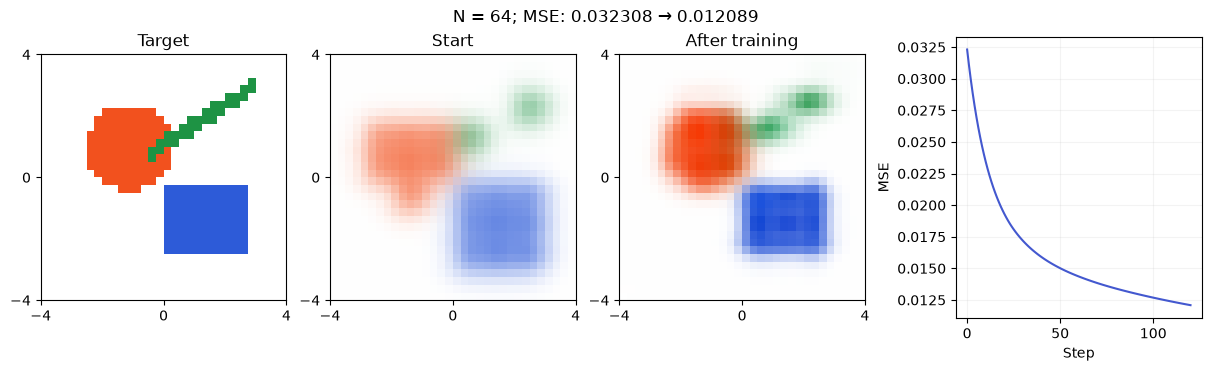

In [2]:
display(fitting_figure(language=LANG))
display(fitting_lab(language=LANG))

## 2. Which Numbers Actually Learn

We keep the familiar scene from lesson 5: coordinates from $-4$ to $4$, $x$ pointing right, $y$ up, and a white background. The spot list runs from front to back. Its order remains fixed throughout training.

Each spot has eight adjustable numbers:

| Parameter | Number of values | Meaning and bounds in this experiment |
|---|---:|---|
| $\mu_x,\mu_y$ | 2 | Center in scene coordinates, from $-4$ to $4$ |
| $\sigma_x,\sigma_y$ | 2 | Scales in the same units, from $0.2$ to $3$ |
| $c_R,c_G,c_B$ | 3 | Numerical RGB channels, from $0$ to $1$ |
| $o$ | 1 | Opacity at the center, from $0$ to $1$ |

The angle stays at zero. Spots can stretch horizontally and vertically, but cannot rotate yet. The algorithm also keeps spot count and layer order fixed. For $64$ spots, there are $64\cdot8=512$ trainable numbers. The background is not trained.

We deliberately kept this model small. It can already reconstruct an image while leaving the whole error path inspectable. Rotation would expand its family of shapes, but require another parameter and its gradient.

## 3. From Parameters Back to a Pixel

For spot $i$ and a pixel at $(x,y)$, we use the same weight as before:

$$
G_i(x,y)=\exp\left[-\frac12\left(
\left(\frac{x-\mu_{x,i}}{\sigma_{x,i}}\right)^2+
\left(\frac{y-\mu_{y,i}}{\sigma_{y,i}}\right)^2\right)\right].
$$

The index $i$ simply selects a spot from the list. The calculation subtracts the center, divides each displacement by its corresponding scale, squares both results, and adds them. Dividing that sum by $-2$ and taking the exponential gives the weight. It is the lesson 3 formula, now repeated for every spot.

For example, pixel $(1,0)$ and a spot centered at $(0,0)$ with scales $(1,2)$ give a simple example. Relative displacements are $1/1=1$ and $0/2=0$. Their squared sum is $1+0=1$, the exponent is $-0.5$, and the weight is $0.606530660$. At opacity $o=0.5$, local opacity is

$$
\alpha_i=o_iG_i=0.5\cdot0.606530660=0.303265330.
$$

Next comes lesson 5's compositing. $T_i$ is the fraction still uncovered by earlier spots before layer $i$. Before the first layer, $T_1=1$. Each layer adds $T_i\alpha_i\mathbf c_i$ to the pixel and leaves $T_{i+1}=T_i(1-\alpha_i)$ for the next. Bold $\mathbf c_i$ means three color values; the same number $T_i\alpha_i$ multiplies each one.

For three local opacities $0.5,0.25,0.2$:

| Before layer | $T_i$ | Its weight $T_i\alpha_i$ | Remaining afterward |
|---|---:|---:|---:|
| 1 | $1$ | $1\cdot0.5=0.5$ | $1\cdot0.5=0.5$ |
| 2 | $0.5$ | $0.5\cdot0.25=0.125$ | $0.5\cdot0.75=0.375$ |
| 3 | $0.375$ | $0.375\cdot0.2=0.075$ | $0.375\cdot0.8=0.3$ |

The background receives the final $0.3$. Weights sum to $0.5+0.125+0.075+0.3=1$. With red, blue, and green spot colors and a white background, the result is $(0.8,0.375,0.425)$: red is $0.5+0.3$, green is $0.075+0.3$, and blue is $0.125+0.3$.

In [3]:
alpha = [0.5, 0.25, 0.2]
colors = np.array([[1, 0, 0], [0, 0, 1], [0, 1, 0]], dtype=float)
T, pixel = 1.0, np.zeros(3)
for a, color in zip(alpha, colors):
    pixel += T * a * color
    T *= 1 - a
pixel += T * np.ones(3)
print("pixel:", pixel, "background weight:", T)
assert np.allclose(pixel, [0.8, 0.375, 0.425])

pixel: [0.8   0.375 0.425] background weight: 0.30000000000000004


## 4. Where the Image Lives in the Arrays

One color contains three numbers. An image row contains $W$ colors; the image contains $H$ rows. Thus its RGB array shape is $(H,W,3)$. Here that is $(32,32,3)$, or $32\cdot32\cdot3=3072$ numerical channels.

Centers form an $(N,2)$ table, scales another $(N,2)$ table, colors an $(N,3)$ table, and opacities an $(N,)$ array. With $N=64$, the center table holds $128$ numbers. Array shape describes data organization, not the spatial shape of a spot.

On this teaching grid, the outermost pixel centers lie at $-4$ and $4$. For column index $k$ from $0$ through $W-1$,

$$
x_k=-4+\frac{8k}{W-1}.
$$

The segment length is $8=4-(-4)$. There are $W-1$ gaps between $W$ points, so spacing is $8/(W-1)$. At $W=5$, coordinates are $-4,-2,0,2,4$. At $W=32$, spacing is approximately $0.258065$. The vertical axis uses the same rule.

In Python, the bottom row has $y=-4$; figures use `origin="lower"`. Ordinary image files place their top row first, so loading one reverses its rows. This is a coordinate convention, not a learned transformation.

For clarity, the renderer below uses a loop. Each spot is evaluated at every pixel at once. `[..., None]` adds a short axis of length $1$: weights shaped $(H,W)$ become $(H,W,1)$, allowing one weight to multiply all three color channels. This is **broadcasting**, repeating a shared multiplier along the missing axis.

In [4]:
def render_with_loop(parameters, size=32):
    axis = torch.linspace(-4, 4, size, dtype=torch.float64)
    yy, xx = torch.meshgrid(axis, axis, indexing="ij")
    T = torch.ones((size, size), dtype=torch.float64)
    image = torch.zeros((size, size, 3), dtype=torch.float64)
    for i in range(len(parameters["centers"])):
        cx, cy = parameters["centers"][i]
        sx, sy = parameters["scales"][i]
        q = ((xx - cx) / sx).square() + ((yy - cy) / sy).square()
        weight = torch.exp(-q / 2)
        alpha = parameters["opacity"][i] * weight
        image = image + (T * alpha)[..., None] * parameters["colors"][i]
        T = T * (1 - alpha)
    return image + T[..., None]  # white background: [1, 1, 1]

target = make_target("shapes", size=32)
parameters = initialize(target, count=64, seed=7, placement="grid", scale=0.55)
with small_cpu_work():
    a = render_with_loop(parameters)
    b = render_torch(parameters)
print("largest renderer difference:", (a - b).abs().max().item())
assert torch.allclose(a, b, atol=1e-12, rtol=1e-12)
print({name: tuple(value.shape) for name, value in parameters.items()})

largest renderer difference: 5.551115123125783e-16
{'centers': (64, 2), 'scales': (64, 2), 'colors': (64, 3), 'opacity': (64,)}


The main module evaluates the same operations for all layers together. `torch.cumprod(1-alpha, dim=0)` successively multiplies the fractions remaining after each layer: $0.5,0.375,0.3$ in the example above. Adding an initial one and shifting the list gives values **before** the layers: $1,0.5,0.375$. Compositing is unchanged; the check above compares both versions.

This renderer stores every spot's weight at every pixel. With $128$ spots on a $32\times32$ grid, that is already $131072$ weights. Larger images quickly increase the volume, and training stores additional intermediates for backward computation. The small resolution keeps the experiment clear and quick on a CPU. This is not yet the fast GPU renderer used by 3DGS.

## 5. How Pixel Error Moves a Spot's Color

Mean squared error now covers every pixel and all three channels:

$$
L=\frac{1}{3HW}\sum_{v=1}^{H}\sum_{u=1}^{W}\sum_{c\in\{R,G,B\}}
(C_{v,u,c}-Y_{v,u,c})^2.
$$

$C$ is the rendered image and $Y$ the target. Here $u,v$ are column and row indices, not relative displacements from the Gaussian formula. The three sums mean three nested traversals: rows, columns, and channels. At each entry, the target channel is subtracted and the difference squared; dividing the total by the channel count $3HW$ gives the mean.

One pixel makes the connection to a parameter visible. A red spot is in front, a blue spot behind it; both have local opacity $0.5$, with a white background. The rendered color is $C=(0.75,0.25,0.5)$ and the target is $Y=(0.6,0.3,0.6)$. Residuals are $(0.15,-0.05,-0.1)$, squares are $(0.0225,0.0025,0.01)$, and their mean is $L=0.035/3=0.011666667$.

Only the first spot's red color channel, called $c_{1,R}$, changes in this example. Being in front, its pixel weight is $T_1\alpha_1=1\cdot0.5=0.5$. Lowering its red channel by $0.01$ lowers the image's red channel by $0.005$.

The chain rule gives

$$
\frac{dL}{dc_{1,R}}=\frac{2(C_R-Y_R)}{3}\cdot0.5
=\frac{2\cdot0.15}{3}\cdot0.5=0.05.
$$

The first factor is the derivative of mean squared error with respect to the image's red channel. The second is the spot color's influence on that channel. At $\eta=0.4$, the red parameter changes from $1$ to $1-0.4\cdot0.05=0.98$. The pixel's red channel becomes $0.75-0.5\cdot0.02=0.74$, closer to the desired $0.6$. New loss is $(0.14^2+(-0.05)^2+(-0.1)^2)/3=0.0107$.

In the actual experiment, this influence is summed across all pixels. For a remote or occluded spot, $T_i\alpha_i$ is often small, giving its color a weak gradient. A spot completely blocked by an opaque foreground layer contributes no visible color, so that pixel tells us nothing about it.

In [5]:
front_red = torch.tensor(1.0, dtype=torch.float64, requires_grad=True)
pixel = torch.stack([0.5 * front_red + 0.25,
                     torch.tensor(0.25, dtype=torch.float64),
                     torch.tensor(0.5, dtype=torch.float64)])
pixel_target = torch.tensor([0.6, 0.3, 0.6], dtype=torch.float64)
pixel_loss = (pixel - pixel_target).square().mean()
pixel_loss.backward()
print("loss:", pixel_loss.item(), "red gradient:", front_red.grad.item())
assert abs(front_red.grad.item() - 0.05) < 1e-12

loss: 0.011666666666666667 red gradient: 0.05


## 6. What About Position, Scale, and Opacity?

These first change $G$ and $\alpha$, rather than the final color directly. For example, increasing $o$ by a small $h$ raises $\alpha=oG$ by $hG$: local slope $G$. Raising the weight by $h$ raises $\alpha$ by $oh$: slope $o$.

Increasing $\alpha$ does not merely add the spot: it also covers whatever is behind it. For one layer and the already-composited color behind it, $\mathbf B$, we can write $\mathbf C=\alpha\mathbf c+(1-\alpha)\mathbf B$. Adding $h$ to $\alpha$ changes color by $h\mathbf c-h\mathbf B=h(\mathbf c-\mathbf B)$. Thus the direction depends on the **difference** between colors, not just the spot's brightness. If both colors match, opacity changes are invisible at that pixel.

The center follows the same chain as lesson 8. For the horizontal center,

$$
\frac{\partial G}{\partial\mu_x}=G\frac{x-\mu_x}{\sigma_x^2}.
$$

The rounded $\partial$ denotes a partial derivative: only the selected parameter changes, with the others held fixed. Along $\mu_x\to(x-\mu_x)\to u\to u^2\to-q/2\to G$, the two negative factors cancel, leaving the familiar result. At point $(1,0)$ with scale $1$, this is $0.606530660\cdot1/1=0.606530660$.

Scale affects a division. If $u=d/\sigma$, a small scale increase reduces the magnitude of nonzero $u$. Fraction arithmetic gives

$$
\frac{d/(\sigma+h)-d/\sigma}{h}
=\frac{-d}{\sigma(\sigma+h)}
\longrightarrow-\frac{d}{\sigma^2}.
$$

For the first expression, a common denominator in the numerator gives $d\sigma-d(\sigma+h)=-dh$; the factor $h$ cancels. As $h$ tends to zero, the denominator becomes $\sigma^2$. Multiplying this local slope by $2u$, $-1/2$, and $G$ gives

$$
\frac{\partial G}{\partial\sigma_x}
=G\frac{(x-\mu_x)^2}{\sigma_x^3}.
$$

One factor of $1/\sigma_x$ came from $u$, two from the derivative of the division. The squared displacement came from two identical factors of $d$. At $d=1,\sigma_x=1$, the slope is again $0.606530660$. At the center, $d=0$ makes it zero: changing scale does not change peak height. Vertical parameters follow the same operations with $y$ replacing $x$.

PyTorch connects these local changes to each pixel's color and error. We do not write one enormous formula for all $512$ parameters. The code specifies familiar operations, and the backward pass sums their paths of influence.

### One Complete Backward Path to Three Parameters

The pieces can now be joined numerically. The foreground spot is red, $\mathbf c=(1,0,0)$, centered at $(0,0)$ with scales $(1,2)$ and opacity $o=0.5$. The pixel lies at $(1,0)$. The already-composited color behind it is $\mathbf B=(0.5,0.5,1)$, while the target asks for $\mathbf Y=(0.6,0.3,0.6)$. Background color and target stay fixed. Loss covers this one pixel, averaged over its three channels.

Weight is $G=0.606530660$, and local opacity is $\alpha=0.5G=0.303265330$. Compositing gives

$$
\begin{aligned}
C_R&=0.303265330\cdot1+0.696734670\cdot0.5=0.651632665,\\
C_G&=0.303265330\cdot0+0.696734670\cdot0.5=0.348367335,\\
C_B&=0.303265330\cdot0+0.696734670\cdot1=0.696734670.
\end{aligned}
$$

Subtracting the target gives residuals $(0.051632665,0.048367335,0.096734670)$. Each channel's mean-square slope is twice its residual divided by three: $(0.034421777,0.032244890,0.064489780)$.

The color slope with respect to $\alpha$ is the difference between foreground and background colors: $\mathbf c-\mathbf B=(0.5,-0.5,-1)$. The single parameter $\alpha$ affects all three channels, so their paths add:

$$
\begin{aligned}
\frac{dL}{d\alpha}
&=0.034421777\cdot0.5+0.032244890\cdot(-0.5)+0.064489780\cdot(-1)\\
&=0.017210889-0.016122445-0.064489780\\
&=-0.063401337.
\end{aligned}
$$

The red channel alone asks for a weaker foreground layer, but green and blue together ask more strongly for a stronger one. Their total slope is negative: a small increase in $\alpha$ reduces this loss.

The remaining path reaches the spot's parameters. In $\alpha=oG$, the local slope with respect to $o$ is $G$, and with respect to $G$ it is $o$. The local slopes of $G$ with respect to $\mu_x$ and $\sigma_x$ at this point both equal $0.606530660$, as calculated above. Thus

$$
\begin{aligned}
\frac{dL}{do}&=(-0.063401337)\cdot0.606530660=-0.038454855,\\
\frac{dL}{d\mu_x}&=(-0.063401337)\cdot0.5\cdot0.606530660=-0.019227427,\\
\frac{dL}{d\sigma_x}&=(-0.063401337)\cdot0.5\cdot0.606530660=-0.019227427.
\end{aligned}
$$

At $\eta=0.1$, one simultaneous update adds about $0.003845485$ to opacity and $0.001922743$ each to horizontal center and scale. The first strengthens the spot, the second moves it toward the pixel, and the third widens it. All three changes increase its contribution here. Vertical slopes are zero because the pixel lies at the center's height. This explains one pixel; training an image adds contributions from other pixels, including opposing ones.

The intermediate numbers shown here are rounded for readability. Calculations retain full precision, so the last digit of a displayed sum can differ.

In [6]:
opacity = torch.tensor(0.5, dtype=torch.float64, requires_grad=True)
cx = torch.tensor(0.0, dtype=torch.float64, requires_grad=True)
sx = torch.tensor(1.0, dtype=torch.float64, requires_grad=True)
G = torch.exp(-0.5 * ((1 - cx) / sx).square())
alpha = opacity * G
red = torch.tensor([1., 0., 0.], dtype=torch.float64)
behind = torch.tensor([0.5, 0.5, 1.], dtype=torch.float64)
wanted = torch.tensor([0.6, 0.3, 0.6], dtype=torch.float64)
C = alpha * red + (1 - alpha) * behind
L = (C - wanted).square().mean()
L.backward()
print("dL/do, dL/dcx, dL/dsx:", opacity.grad.item(), cx.grad.item(), sx.grad.item())
assert abs(opacity.grad.item() + 0.03845485464224445) < 1e-12
assert abs(cx.grad.item() + 0.019227427321122224) < 1e-12
assert abs(sx.grad.item() - cx.grad.item()) < 1e-12

dL/do, dL/dcx, dL/dsx: -0.03845485464224445 -0.019227427321122224 -0.019227427321122224


## 7. The Complete Loop and Valid Parameter Ranges

Every trainable number now has a gradient. For any such number $p$, the update is $p_{\text{new}}=p-\eta g_p$, where $g_p$ is the derivative of total loss with respect to that number. The main experiment uses the same $\eta=4$ for all groups. This is a convenient teaching choice, not a universal setting for arbitrary images and coordinate scales.

An update may leave the valid range. Color $1.03$ is returned to $1$, opacity $-0.04$ to $0$, and scale $0.17$ to $0.2$. This is range clipping, or `clamp`. We explicitly apply it **after** the gradient step without recording a graph. The result is gradient descent followed by projection back into the allowed region.

Projection may hold a parameter at a boundary; it does not guarantee a loss decrease. Minimum scale $0.2$ prevents division by zero and nearly invisible narrow spots. It also limits fine detail. Other representations of positive scales and bounded opacity exist, but this program uses no hidden parameter transformation.

MSE before / after: 0.03230836198958174 0.012089343138795219


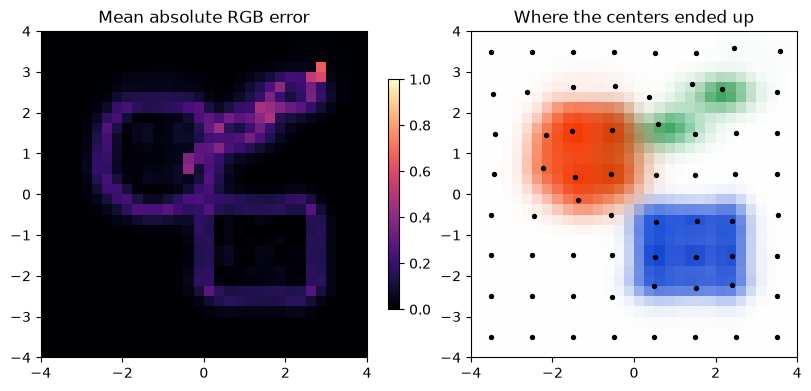

In [7]:
target_array = make_target("shapes", size=32)
target_tensor = torch.tensor(target_array, dtype=torch.float64)
parameters = initialize(target_array, count=64, seed=7, placement="grid", scale=0.55)
optimizer = torch.optim.SGD(list(parameters.values()), lr=4.0)
losses = []

with small_cpu_work():
    for step in range(121):
        optimizer.zero_grad(set_to_none=True)
        image = render_torch(parameters, height=32)
        loss = (image - target_tensor).square().mean()
        losses.append(loss.item())
        if step == 120:
            break
        loss.backward()
        optimizer.step()
        with torch.no_grad():
            parameters["centers"].clamp_(-4, 4)
            parameters["scales"].clamp_(0.2, 3)
            parameters["colors"].clamp_(0, 1)
            parameters["opacity"].clamp_(0, 1)

print("MSE before / after:", losses[0], losses[-1])
assert losses[-1] < losses[0]
result = demo_fit()
assert np.allclose(image.detach().numpy(), result["image"], atol=1e-12)
display(detail_figure(result, language=LANG))

`detach()` in the final check separates a result from its graph so it can be inspected as an ordinary array. This is appropriate **after** computing gradients or when saving an image. Placing `detach()` between the renderer and the loss would break training.

There is no random pixel selection: each step uses all $3072$ channels. Grid initialization is deterministic too. Random placement uses `seed=7` so repeated runs in the same environment start with the same spots. A seed identifies a generator's initial state, not scene quality. NumPy and the browser use different generators, so identical seed labels do not promise identical random arrangements across them; grid mode provides the shared numerical example.

This model compares numerical RGB values in $0..1$ without color-space conversion, following the first block's convention. Physically correct color mixing and photographic comparisons will require separate attention to color space.

## 8. Too Few Spots, Poor Placement, or Tiny Initial Scales

Sixteen spots have only $128$ parameters. They must cover large areas, so the thin green stripe and straight boundaries get lost. With $128$ spots, there are $1024$ parameters and more freedom to place small elements near edges. This does not promise that every run with more spots will be better: positions, scales, order, and training time matter too.

The comparison below holds the target, pixel grid, initial scale $0.55$, learning rate $4$, and $120$ updates fixed. Only spot count changes. Naturally, that also changes the initial center grid. The table includes initial loss so any advantage from initialization remains visible.

There are two further causes of poor results:

- If all centers start near the middle, empty boundary regions may supply almost no gradient. The model first has to “reach” the missing areas.
- If initial scales are too small relative to spot spacing, gaps remain. Excessively broad spots overlap strongly and initially paint blurry clouds of color instead.

The absolute-difference map shows where errors occur; the MSE graph shows their overall trend. Falling MSE and a still-missing thin detail are perfectly compatible: large flat regions may improve more than the small detail does.

N= 16; parameters= 128; MSE 0.068029 -> 0.022499


N= 64; parameters= 512; MSE 0.032308 -> 0.012089


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.03785843788907092..1.0000000000000004].


N=128; parameters=1024; MSE 0.034382 -> 0.009793


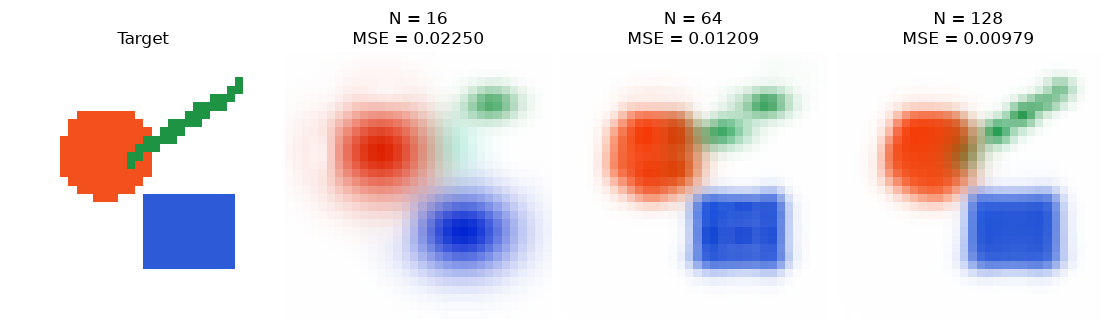

In [8]:
comparison = []
for count in [16, 64, 128]:
    run = demo_fit(count=count)
    comparison.append(run)
    print(f"N={count:3d}; parameters={8*count:4d}; MSE {run['history'][0]:.6f} -> {run['history'][-1]:.6f}")

import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 4, figsize=(11, 3.2), layout="constrained")
axes[0].imshow(make_target(), origin="lower")
axes[0].set_title("Образец" if LANG == "ru" else "Target")
for ax, run in zip(axes[1:], comparison):
    ax.imshow(run["image"], origin="lower")
    ax.set_title(f"N = {run['settings']['count']}\nMSE = {run['history'][-1]:.5f}")
for ax in axes:
    ax.axis("off")
display(fig)
plt.close(fig)

## 9. A Personal Image and a Saved Scene

Built-in targets provide repeatable comparisons. The same training function accepts any RGB array shaped $(H,W,3)$ with values from $0$ to $1$. `load_image` opens a local file, downsizes it to a small grid while preserving its aspect ratio, and adds white padding. Transparent regions are also composited onto white. Strong downsampling removes fine details **before** training—the model cannot recover detail absent from its target.

The example leaves the path as `None`, so it uses the built-in image. If `image_path` contains a local file path, that image is fitted instead. The file is not uploaded.

The output is more than a PNG. JSON stores centers, scales, colors, and opacities in the same format accepted by the lesson 5 editor. Angles remain $0$ and layer order stays unchanged. The file can render the scene again or be edited manually. It does not itself store the target, loss history, or training-loop state, so experiment settings are saved alongside it.

Results are written to `Path.cwd() / "image-fit-result"`: the `image-fit-result` folder inside Python's current working directory. With `save_files=False`, the result remains in memory; `True` writes `gaussian-scene.json`, `experiment.json`, `target.png`, and `result.png`.

In [9]:
image_path = None  # Example: course_root / "my-image.png"
chosen_target = make_target("shapes") if image_path is None else load_image(image_path, size=32)
chosen_result = demo_fit() if image_path is None else fit_image(chosen_target, count=64, steps=120)

# Files are written under Path.cwd() when save_files is True.
save_files = False
if save_files:
    import json
    from PIL import Image
    folder = Path.cwd() / "image-fit-result"
    folder.mkdir(exist_ok=True)
    (folder / "gaussian-scene.json").write_text(chosen_result["scene"], encoding="utf-8")
    experiment = dict(chosen_result["settings"], history=chosen_result["history"],
                      resolution=list(chosen_target.shape[:2]), bounds=[-4, 4, -4, 4])
    (folder / "experiment.json").write_text(json.dumps(experiment, indent=2), encoding="utf-8")
    for filename, array in [("target.png", chosen_target), ("result.png", chosen_result["image"])]:
        rgb = np.rint(np.clip(np.flipud(array), 0, 1) * 255).astype(np.uint8)
        Image.fromarray(rgb).save(folder / filename)

from gaussian_math import load_scene_json, render_layers
layers, background = load_scene_json(chosen_result["scene"])
roundtrip = render_layers(layers, background, size=32)
print("exported layers:", len(layers))
print("largest roundtrip difference:", np.max(np.abs(roundtrip - chosen_result["image"])))
assert np.allclose(roundtrip, chosen_result["image"], atol=1e-12)

exported layers: 64
largest roundtrip difference: 1.4432899320127035e-15


## 10. What This Project Does, and What Is Still Missing

We now have a program that fits a numerical description of an image. Pixels go in; a collection of soft spots comes out. Rendering that collection on a finer grid is possible, but adds no new observations. A smooth, larger rendering does not prove that original photographic detail was recovered.

This is **image reconstruction with Gaussians**, not an implementation of the 2D Gaussian Splatting method for reconstructing surfaces in a three-dimensional scene. There is no depth, camera, projection, or novel viewpoint here. Layer order means list order, not distance from a camera. Those differences will matter in the next block.

Not every image can be described exactly by a fixed number of these spots. Even when a good description exists, ordinary gradient descent may fail to find it from a particular initialization. Low MSE means close agreement between selected numbers on a selected grid; it guarantees neither unique parameters nor a perfect visual result.

The next step adds space and a camera. Spots will no longer live directly on the image plane: their positions and shapes will pass through a projection. But the backward path will remain familiar: image → loss → gradients → scene parameters.

## 11. Three Small Investigations

**Count.** The same target, $16$ versus $128$ spots, and the same $120$ updates. The table above gives lower loss for the larger set. On the checker target, the advantage may look different: cell size and center placement matter. The difference map reveals which areas improved.

**Initial scale.** With $64$ spots, the scales $0.2$, $0.55$, and $1.5$ produce a useful comparison. Gaps or strong overlaps are visible before training. Afterward, the comparison concerns the speed of MSE reduction and the shape of the remaining error.

**Longer or different.** For an unlucky start, another $120$ updates can be compared with a fresh initialization. A falling loss during continued training does not mean the best possible spot collection has been found. Restarting sometimes helps and sometimes discards a useful result.

<details>
<summary>Explanation: why more spots does not mean twice as good</summary>

Extra spots provide parameters but still need useful locations. They may overlap each other, paint the same thing, or remain nearly invisible. This program never adds new spots specifically where errors remain and never deletes unhelpful ones. Such operations change the collection itself and will be covered separately in the full 3DGS block.

</details>

<details>
<summary>Explanation: almost-zero opacity and center movement</summary>

Position changes $G$, then $\alpha=oG$. When $o$ is almost zero, a weight change barely affects local opacity: the factor $o$ suppresses this gradient path. Opacity itself can still receive a gradient through the factor $G$ if the spot lies near a useful region. A faded spot is therefore not necessarily lost forever, but one that is both invisible and distant often learns slowly.

</details>

<details>
<summary>Explanation: what to compare between runs</summary>

The target, resolution, loss function, and color scale should agree. Equal step counts do not mean equal time: more spots require more computation. Saving both, along with initial and final MSE, settings, and images, makes the comparison useful. One successful seed does not establish robustness; repeated runs reveal how strongly initialization affects the result.

</details>